### E-Commerce Review Intelligence System

**MBA Business Analytics Assignment**  
**Dataset:** Amazon Fine Food Reviews

This notebook develops an end-to-end review intelligence workflow that translates unstructured customer feedback into actionable product and customer-experience insights.

#### Business Problem

E-commerce leaders receive thousands of product reviews, but manually reading them does not scale. The business needs a reliable way to identify how customers feel, understand the themes behind that feedback, and prioritize products where negative experiences create the greatest commercial risk.

**Decision question:** Which products and customer-experience themes should management investigate first to protect customer satisfaction and future revenue?



#### Dataset Description

This analysis uses the **Amazon Fine Food Reviews dataset.** Each record contains a product identifier, a 1-5 star rating, a review summary, and the full review text. Ratings provide a practical sentiment proxy: scores 1-2 are negative, 3 is neutral, and 4-5 are positive.



| # | Column | Description |
|---:|---|---|
| 1 | `Id` | Unique row or review identifier |
| 2 | `ProductId` | Unique identifier for the food or gourmet product |
| 3 | `UserId` | Unique identifier for the reviewer |
| 4 | `ProfileName` | Name or nickname of the reviewer |
| 5 | `HelpfulnessNumerator` | Number of users who found the review helpful |
| 6 | `HelpfulnessDenominator` | Total number of votes on whether the review was helpful |
| 7 | `Score` | Star rating from 1 to 5 |
| 8 | `Time` | Timestamp of the review |
| 9 | `Summary` | Short text summary or title of the review |
| 10 | `Text` | Full text content of the customer review |

In [1]:
# Experiment 1                 Experiment 2                 Experiment 3

# TF-IDF                       Word Embeddings              Pretrained DistilBERT
#    ↓                              ↓                              ↓
# Logistic Regression             LSTM                       Self-Attention
#    ↓                              ↓                              ↓
# Sentiment                     Sentiment                       Sentiment

# Statistical NLP             Sequential Deep Learning      Transformer NLP

In [2]:
# `Experiment 1`
# "The food is not very good"
#         ↓ TF-IDF
# Large sparse vector
#         ↓
# Logistic Regression
#         ↓
# Predicted Sentiment

#  ---------------------------------------------------------

# `Experiment 2`
# "The food is not very good"
#        ↓ Word tokenizer
# [15, 83, 9, 37, 24, 51]
#        ↓ Embedding
# Dense word vectors
#        ↓ LSTM
# Sequential representation
#        ↓ Dense + Softmax
# Predicted Sentiment
# Negative / Neutral / Positive

#  ---------------------------------------------------------


In [3]:
# `Experiment 3`
# "The food is not very good"
#            ↓
# DistilBERT Tokenizer
#            ↓
# Subword Tokens
# + Attention Mask
#            ↓
# Pretrained DistilBERT
#    Transformer Layers
#            ↓
# Self-Attention
#            ↓
# Contextual Representation
#            ↓
# Classification Head
#            ↓
# Negative / Neutral / Positive

#  ---------------------------------------------------------

In [4]:
#                     RAW REVIEWS
#                          │
#                          ▼
#               ┌────────────────────┐
#               │ Exploratory Data   │
#               │ Analysis           │
#               └─────────┬──────────┘
#                         │
#                         ▼
#              Cleaning + Label Creation
#                         │
#               ┌─────────┴──────────┐
#               │                    │
#               ▼                    ▼
#       CLASSICAL NLP           TRANSFORMER
#               │                    │
#         TF-IDF / LSTM          Tokenizer
#           ┌───┴───┐                │
#           ▼       ▼                ▼
#      Logistic                     DistilBERT
#      Regression                     │
#           │       │                 │
#           └───────┴────────┬────────┘
#                            ▼
#                    MODEL EVALUATION
#                            │
#       ┌────────────────────┼──────────────────┐
#       ▼                    ▼                  ▼
#    Accuracy             Macro F1        Confusion Matrix
#                            │
#                            ▼
#                      ERROR ANALYSIS
#                            │
#                            ▼
#                       BEST MODEL
#                            │
#                            ▼
#                        BERTopic
#                            │
#                            ▼
#                 TOPIC × SENTIMENT
#                            │
#                            ▼
#                    BUSINESS INSIGHTS
#                            │
#                ┌───────────┼────────────┐
#                ▼           ▼            ▼
#              Product     Marketing     Service
#            Improvement    Insights    Improvement

1. Importing Libraries

In [5]:
!python3 -m pip install torch transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn

In [6]:
%pip install "numpy<2.8"

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import random

import torch


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [9]:
from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding
)

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device: ", device)

Device:  mps


In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

2. Importing Datasets

In [12]:
df = pd.read_csv("./Reviews.csv")

In [13]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


Rows: 568454, Columns: 10


3. Examining Dataset

In [14]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [15]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


Missing Values

In [17]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [18]:
df = df.dropna(subset=["Summary"])
df = df.reset_index(drop=True)

In [19]:
print("Total duplicated rows in the dataframe:", df.duplicated().sum())

Total duplicated rows in the dataframe: 0


In [20]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29744
3     42638
4     80655
5    363122
Name: count, dtype: int64

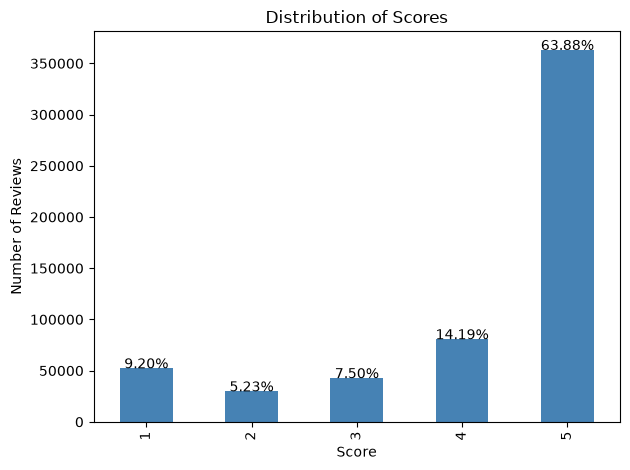

In [21]:
# Plot the distribution of review scores
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Score"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

4. Convert Rating into Sentiment
* [1, 2] -> Negative
* [ 3  ]    -> Neutral
* [4, 5] -> Positive

In [22]:
def create_sentiment(score: int) -> str:
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

In [23]:
df["Sentiment"] = df["Score"].apply(create_sentiment)

In [24]:
df[["Score", "Sentiment"]].head(10)

,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive
5,4,Positive
6,5,Positive
7,5,Positive
8,5,Positive
9,5,Positive


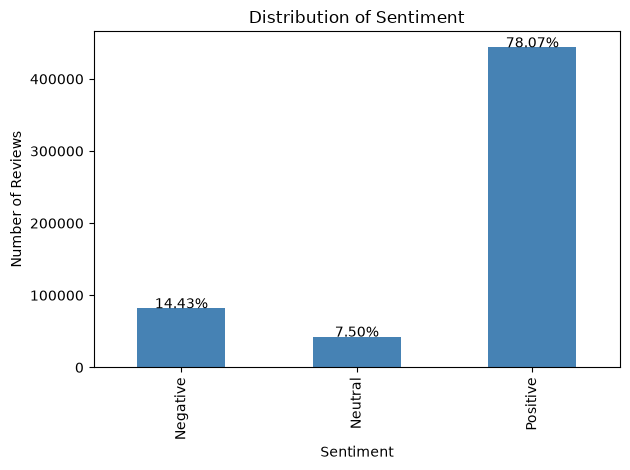

In [25]:
# Plot the distribution of Sentiment
df["Sentiment"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Sentiment"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )


plt.title("Distribution of Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Inference: Class Highly Imbalanced -
* Positive - 78 %
* Neutral - 7.5%
* Negative - 14.5 %

Merging Summary with Text in Review Column appended by comma(',')

In [26]:
df["Review"] = (df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
df["Review"].head()

0    Good Quality Dog Food , I have bought several ...
1    Not as Advertised , Product arrived labeled as...
2    "Delight" says it all , This is a confection t...
3    Cough Medicine , If you are looking for the se...
4    Great taffy , Great taffy at a great price.  T...
Name: Review, dtype: str

5. Basic Text Preprocessing

In [27]:
import re

In [28]:
def clean_text_transformer(text: str) -> str:
    text = str(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Normalize repeated whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [29]:
df["Review"] = df["Review"].apply(clean_text_transformer)

* Inference : Stopwords should not be removed as it will remove the sentiment in the review comments

In [30]:
# TensorFlow works more naturally with numeric classes.
label_map = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

In [31]:
df["label"] = df["Sentiment"].map(label_map)

In [32]:
df[["Sentiment", "label"]].head()

,Sentiment,label
0,Positive,2
1,Negative,0
2,Positive,2
3,Negative,0
4,Positive,2


In [33]:
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

6. Train / Validation / Test Split

* 70% training
* 15% validation
* 15% testing

Experiment 3: Transformer

In [34]:
print(df.columns.tolist())
print("'label' exists:", "label" in df.columns)
print("'Sentiment' exists:", "Sentiment" in df.columns)

['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'Sentiment', 'Review', 'label']
'label' exists: True
'Sentiment' exists: True


In [35]:
SAMPLES_PER_CLASS = 3000

required_columns = {"Score", "Summary", "Text"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")
if df.empty or not df["Score"].isin([1, 2, 3, 4, 5]).all():
    raise ValueError("The dataset must contain reviews with scores from 1 to 5.")

df = df.assign(
    label=df["Score"].map({1: 0, 2: 0, 3: 1, 4: 2, 5: 2}),
    Review=(df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
        .str.replace(r"<.*?>", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
)
df["Sentiment"] = df["label"].map({0: "Negative", 1: "Neutral", 2: "Positive"})

samples_per_class = min(SAMPLES_PER_CLASS, int(df["label"].value_counts().min()))
if df["label"].nunique() != 3 or samples_per_class < 10:
    raise ValueError("At least 10 reviews per sentiment class are needed for the stratified splits.")

df = (
    df.groupby("label").sample(n=samples_per_class, random_state=42)
      .sample(frac=1, random_state=42)
      .reset_index(drop=True)
)

print("Trimmed dataset size:", len(df))
print("Samples per class:")
print(df["label"].value_counts().sort_index())

Trimmed dataset size: 9000
Samples per class:
label
0    3000
1    3000
2    3000
Name: count, dtype: int64


In [36]:
train_df, temp_df = train_test_split(
    df[["Review", "label"]],
    test_size=0.3,
    random_state=SEED,
    stratify=df["label"]
)

In [37]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df["label"]
)

In [38]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [39]:
print("Training set size:", len(train_df))
print("Validation set size:", len(val_df))
print("Test set size:", len(test_df))

Training set size: 6300
Validation set size: 1350
Test set size: 1350


#### 7. Choosing DistilBERT as Transformer Model

In [40]:
!python3 -c 'from huggingface_hub import snapshot_download; models=["distilbert-base-uncased"]; [print(f"Downloading {m}...") or snapshot_download(repo_id=m) for m in models]; print("Downloads complete.")'

Fetching 12 files: 100%|█████████████████████| 12/12 [00:00<00:00, 4752.75it/s]
Downloads complete.


In [41]:
MODEL_NAME = "distilbert-base-uncased"

### Tokenization 
> Tokenizer learns Vocabulary

> Sample Tokenization Process

In [42]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

OOV = Out Of Vocabulary.

In [43]:
sample_text = train_df["Review"].iloc[2]
print(sample_text)

Good size, hits the craving , I was a bit skeptical as to how big the bags were, but was satiated in the end. Finding halal gummies like this in the US is not an easy task. Rest assured, they were Zabiha halal. As to the product: the taste of this type of candy is initially sweet due to the granulated sugar after which you begin to taste the flat-cola type of flavor. If you're craving these as bad as I was, it's worth the buy.


In [44]:
tokens = tokenizer.tokenize(sample_text)
print(tokens)

['good', 'size', ',', 'hits', 'the', 'craving', ',', 'i', 'was', 'a', 'bit', 'skeptical', 'as', 'to', 'how', 'big', 'the', 'bags', 'were', ',', 'but', 'was', 'sat', '##iated', 'in', 'the', 'end', '.', 'finding', 'hal', '##al', 'gum', '##mies', 'like', 'this', 'in', 'the', 'us', 'is', 'not', 'an', 'easy', 'task', '.', 'rest', 'assured', ',', 'they', 'were', 'za', '##bi', '##ha', 'hal', '##al', '.', 'as', 'to', 'the', 'product', ':', 'the', 'taste', 'of', 'this', 'type', 'of', 'candy', 'is', 'initially', 'sweet', 'due', 'to', 'the', 'gran', '##ulated', 'sugar', 'after', 'which', 'you', 'begin', 'to', 'taste', 'the', 'flat', '-', 'cola', 'type', 'of', 'flavor', '.', 'if', 'you', "'", 're', 'craving', 'these', 'as', 'bad', 'as', 'i', 'was', ',', 'it', "'", 's', 'worth', 'the', 'buy', '.']


In [45]:
encoded = tokenizer(
    sample_text,
    truncation=True,
    max_length=256
)

In [46]:
print(encoded["input_ids"])

[101, 2204, 2946, 1010, 4978, 1996, 26369, 1010, 1045, 2001, 1037, 2978, 18386, 2004, 2000, 2129, 2502, 1996, 8641, 2020, 1010, 2021, 2001, 2938, 15070, 1999, 1996, 2203, 1012, 4531, 11085, 2389, 16031, 28397, 2066, 2023, 1999, 1996, 2149, 2003, 2025, 2019, 3733, 4708, 1012, 2717, 8916, 1010, 2027, 2020, 23564, 5638, 3270, 11085, 2389, 1012, 2004, 2000, 1996, 4031, 1024, 1996, 5510, 1997, 2023, 2828, 1997, 9485, 2003, 3322, 4086, 2349, 2000, 1996, 12604, 8898, 5699, 2044, 2029, 2017, 4088, 2000, 5510, 1996, 4257, 1011, 15270, 2828, 1997, 14894, 1012, 2065, 2017, 1005, 2128, 26369, 2122, 2004, 2919, 2004, 1045, 2001, 1010, 2009, 1005, 1055, 4276, 1996, 4965, 1012, 102]


Each tokenizer token corresponds to a vocabulary ID.

In [47]:
print(encoded["attention_mask"])

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


The attention mask tells the model which positions contain actual sequence tokens versus padding:
> 1 → real token position

> 0 → padding position

#### Tokenization Length Calculation 

In [48]:
token_lengths = train_df["Review"].apply(
    lambda x: len(
        tokenizer.encode(
            x,
            add_special_tokens=True,
            truncation=False
        )
    )
)

Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


In [49]:
token_lengths.describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    6300.000000
mean      117.983016
std       119.322009
min        20.000000
50%        85.000000
75%       142.000000
90%       229.000000
95%       312.000000
99%       541.010000
max      2884.000000
Name: Review, dtype: float64

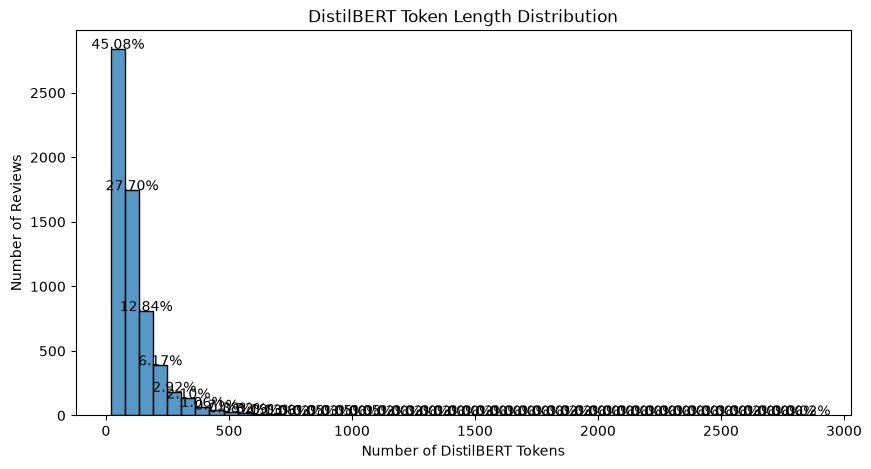

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    token_lengths,
    bins=50
)

# Show percentage on the bars
total = len(token_lengths)
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.xlabel("Number of DistilBERT Tokens")
plt.ylabel("Number of Reviews")
plt.title(
    "DistilBERT Token Length Distribution"
)

plt.show()

In [51]:
MAX_LENGTH = 256

Convert DataFrames into Hugging Face Datasets

In [52]:
train_dataset = Dataset.from_pandas(train_df)

val_dataset = Dataset.from_pandas(val_df)

test_dataset = Dataset.from_pandas(test_df)

In [53]:
train_dataset

Dataset({
    features: ['Review', 'label'],
    num_rows: 6300
})

Creating Tokenizer Function

In [54]:
def tokenize_function(batch):
    return tokenizer(
        batch["Review"],
        truncation=True,
        max_length=MAX_LENGTH
    )

Tokenize all Splits

In [55]:
train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/6300 [00:00<?, ? examples/s]

Map:   0%|          | 0/1350 [00:00<?, ? examples/s]

Map:   0%|          | 0/1350 [00:00<?, ? examples/s]

In [56]:
print(train_tokenized[0])

{'Review': "Stinky and horrible , First impression when I opened these - hmmm. They smell like paint thinner. Not the most enticing smell (y'don't say!) but I gave it a shot anyway. They're super greasy and have a really strange chemical taste to them. The green beans are especially awful. I'd skip these and buy the TERRA brand exotic vegetable chips instead.", 'label': 0, 'input_ids': [101, 27136, 2100, 1998, 9202, 1010, 2034, 8605, 2043, 1045, 2441, 2122, 1011, 17012, 2213, 1012, 2027, 5437, 2066, 6773, 23082, 1012, 2025, 1996, 2087, 4372, 4588, 2075, 5437, 1006, 1061, 1005, 2123, 1005, 1056, 2360, 999, 1007, 2021, 1045, 2435, 2009, 1037, 2915, 4312, 1012, 2027, 1005, 2128, 3565, 26484, 1998, 2031, 1037, 2428, 4326, 5072, 5510, 2000, 2068, 1012, 1996, 2665, 13435, 2024, 2926, 9643, 1012, 1045, 1005, 1040, 13558, 2122, 1998, 4965, 1996, 14403, 4435, 12564, 15415, 11772, 2612, 1012, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

#### Dynamic Padding -
dynamic padding pads each batch only to the longest sequence within that batch.

In [57]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Load Pretrained DistilBERT

In [58]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

Some weights of the model checkpoint at distilbert-base-uncased were not used when initializing DistilBertForSequenceClassification: ['vocab_transform.bias', 'vocab_projector.bias', 'vocab_projector.weight', 'vocab_layer_norm.bias', 'vocab_transform.weight', 'vocab_layer_norm.weight']
- This IS expected if you are initializing DistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['pre_classifier.weight', 'classifier.weight', 'classifi

#### Define Evaluation Metrics

In [59]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average='macro',
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1
    }

#### Training Model

In [60]:
training_args = TrainingArguments(
    output_dir='./distilbert_sentiment',
    learning_rate=2e-5, # lower bcoz we're fine-tuning pretrained weights.

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01, # adds regularization to reduce overfitting.

    evaluation_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_steps=100,

    save_total_limit=2
)

In [61]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

In [62]:
trainer.train()

The following columns in the training set  don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: Review. If Review are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 6300
  Num Epochs = 3
  Instantaneous batch size per device = 16
  Total train batch size (w. parallel, distributed & accumulation) = 16
  Gradient Accumulation steps = 1
  Total optimization steps = 1182


  0%|          | 0/1182 [00:00<?, ?it/s]

/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 0.874, 'learning_rate': 1.830795262267344e-05, 'epoch': 0.25}
{'loss': 0.6185, 'learning_rate': 1.661590524534687e-05, 'epoch': 0.51}
{'loss': 0.6127, 'learning_rate': 1.4923857868020306e-05, 'epoch': 0.76}


The following columns in the evaluation set  don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: Review. If Review are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1350
  Batch size = 16


...

Saving model checkpoint to ./distilbert_sentiment/checkpoint-1182
Configuration saved in ./distilbert_sentiment/checkpoint-1182/config.json


{'eval_loss': 0.5265257358551025, 'eval_accuracy': 0.7903703703703704, 'eval_precision': 0.7920872893699343, 'eval_recall': 0.7903703703703705, 'eval_macro_f1': 0.7910465441917163, 'eval_runtime': 33.1446, 'eval_samples_per_second': 40.731, 'eval_steps_per_second': 2.565, 'epoch': 3.0}


Model weights saved in ./distilbert_sentiment/checkpoint-1182/pytorch_model.bin
tokenizer config file saved in ./distilbert_sentiment/checkpoint-1182/tokenizer_config.json
Special tokens file saved in ./distilbert_sentiment/checkpoint-1182/special_tokens_map.json
Deleting older checkpoint [distilbert_sentiment/checkpoint-394] due to args.save_total_limit


Training completed. Do not forget to share your model on huggingface.co/models =)


Loading best model from ./distilbert_sentiment/checkpoint-1182 (score: 0.7910465441917163).


{'train_runtime': 2035.6281, 'train_samples_per_second': 9.285, 'train_steps_per_second': 0.581, 'train_loss': 0.48530067889218403, 'epoch': 3.0}


TrainOutput(global_step=1182, training_loss=0.48530067889218403, metrics={'train_runtime': 2035.6281, 'train_samples_per_second': 9.285, 'train_steps_per_second': 0.581, 'train_loss': 0.48530067889218403, 'epoch': 3.0})

#### Evaluate on Validation data

In [63]:
val_results = trainer.evaluate(
    val_tokenized
)

print(val_results)

The following columns in the evaluation set  don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: Review. If Review are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1350
  Batch size = 16
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


  0%|          | 0/85 [00:00<?, ?it/s]

{'eval_loss': 0.5265257358551025, 'eval_accuracy': 0.7903703703703704, 'eval_precision': 0.7920872893699343, 'eval_recall': 0.7903703703703705, 'eval_macro_f1': 0.7910465441917163, 'eval_runtime': 33.2639, 'eval_samples_per_second': 40.585, 'eval_steps_per_second': 2.555, 'epoch': 3.0}


In [64]:
test_results = trainer.evaluate(
    test_tokenized
)

print(test_results)

The following columns in the evaluation set  don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: Review. If Review are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1350
  Batch size = 16
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


  0%|          | 0/85 [00:00<?, ?it/s]

{'eval_loss': 0.5476757884025574, 'eval_accuracy': 0.7844444444444445, 'eval_precision': 0.7870109234828323, 'eval_recall': 0.7844444444444445, 'eval_macro_f1': 0.7854652705876811, 'eval_runtime': 34.0436, 'eval_samples_per_second': 39.655, 'eval_steps_per_second': 2.497, 'epoch': 3.0}


In [65]:
pred_output = trainer.predict(
    test_tokenized
)

The following columns in the test set  don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: Review. If Review are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1350
  Batch size = 16
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


  0%|          | 0/85 [00:00<?, ?it/s]

In [66]:
test_logits = pred_output.predictions

Visualise Accuracy

In [67]:
y_pred = np.argmax(
    test_logits,
    axis=1
)

Model Evaluation

In [68]:
y_test = test_df["label"].values

In [69]:
target_names = [
    "Negative",
    "Neutral",
    "Positive"
]


Classification Report

In [70]:
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
))

              precision    recall  f1-score   support

    Negative     0.7954    0.7689    0.7819       450
     Neutral     0.6835    0.7200    0.7013       450
    Positive     0.8821    0.8644    0.8732       450

    accuracy                         0.7844      1350
   macro avg     0.7870    0.7844    0.7855      1350
weighted avg     0.7870    0.7844    0.7855      1350



Confusion Matrix

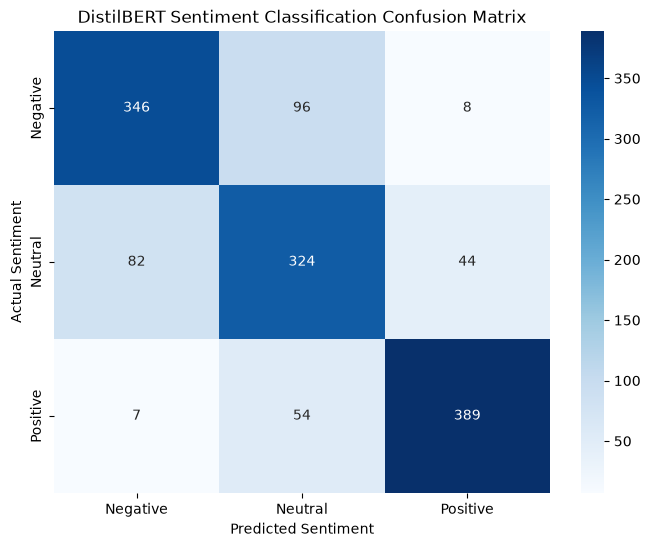

In [71]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Sentiment Classification Confusion Matrix")

plt.show()

Convert Logits to Probabilities

In [72]:
probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()

In [73]:
probabilities[0]

array([0.52058536, 0.47028568, 0.00912901], dtype=float32)

#### Error Analysis

In [74]:
results = pd.DataFrame({
    "Review": test_df["Review"].values,
    "Actual": y_test,
    "Predicted": y_pred,
    "Confidence": probabilities.max(axis=1)
})

In [75]:
results["Actual"] = (
    results["Actual"]
    .map(id2label)
)

results["Predicted"] = (
    results["Predicted"]
    .map(id2label)
)

In [76]:
error = results[
    results["Actual"] != results["Predicted"]
]

In [77]:
error.sort_values(
    by="Confidence",
    ascending=False
).head(20)

,Review,Actual,Predicted,Confidence
1113,"very tasty , Have been looking for a low fat/s...",Neutral,Positive,0.991408
464,"Something my Bengals will happily eat! , I hav...",Neutral,Positive,0.988625
324,"Best Dark Mint Chocolate , This is fabulous ch...",Neutral,Positive,0.984102
40,"Holy Mint! , I really hope that these companie...",Neutral,Positive,0.980287
503,"THE TASTE IS HORRIBLE. , Its god awful nasty i...",Neutral,Negative,0.979802
108,"Virbac CET HEXtra chews Petite , My Maltese-8 ...",Neutral,Positive,0.975135
616,"Tasty and crunchy , This is a nice tasty littl...",Neutral,Positive,0.973521
563,"Can't taste it much.... , It certainly doesn't...",Neutral,Negative,0.972999
1124,"B- , Do not buy this product. At the first tas...",Positive,Negative,0.970000
632,"Looking Forward to the New Kits , I have to ag...",Neutral,Positive,0.968841


Running Test on Sample Sentences

In [78]:
def predict_sentiment(text):

    text = clean_text_transformer(text)

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True
    )

    model_device = next(
        model.parameters()
    ).device

    inputs = {
        key: value.to(model_device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():

        output = model(
            **inputs
        )

    probs = torch.softmax(
        output.logits,
        dim=1
    )[0]

    predicted_id = int(
        torch.argmax(probs)
    )

    return {
        "sentiment":
            id2label[predicted_id],

        "confidence":
            float(probs[predicted_id]),

        "probabilities": {
            id2label[i]: float(probs[i])
            for i in range(3)
        }
    }

In [79]:
predict_sentiment(
    "Excellent product and very fast delivery"
)

{'sentiment': 'Positive',
 'confidence': 0.9813115000724792,
 'probabilities': {'Negative': 0.004164466634392738,
  'Neutral': 0.014524075202643871,
  'Positive': 0.9813115000724792}}

In [80]:
predict_sentiment(
    "Absolutely awful quality and I would never buy this again"
)

{'sentiment': 'Negative',
 'confidence': 0.969980001449585,
 'probabilities': {'Negative': 0.969980001449585,
  'Neutral': 0.017645958811044693,
  'Positive': 0.012374104000627995}}

In [81]:
predict_sentiment(
    "The food tastes amazing but the package arrived damaged and late"
)

{'sentiment': 'Neutral',
 'confidence': 0.6327083110809326,
 'probabilities': {'Negative': 0.345683217048645,
  'Neutral': 0.6327083110809326,
  'Positive': 0.021608475595712662}}

Saving the Model

In [82]:
trainer.save_model("./final_distilbert_sentiment")

Saving model checkpoint to ./final_distilbert_sentiment
Configuration saved in ./final_distilbert_sentiment/config.json
Model weights saved in ./final_distilbert_sentiment/pytorch_model.bin
tokenizer config file saved in ./final_distilbert_sentiment/tokenizer_config.json
Special tokens file saved in ./final_distilbert_sentiment/special_tokens_map.json


In [83]:
tokenizer.save_pretrained("./final_distilbert_sentiment")

tokenizer config file saved in ./final_distilbert_sentiment/tokenizer_config.json
Special tokens file saved in ./final_distilbert_sentiment/special_tokens_map.json


('./final_distilbert_sentiment/tokenizer_config.json',
 './final_distilbert_sentiment/special_tokens_map.json',
 './final_distilbert_sentiment/vocab.txt',
 './final_distilbert_sentiment/added_tokens.json',
 './final_distilbert_sentiment/tokenizer.json')

In [84]:
experiment_3_results = {
    "Model":
        "Fine-tuned DistilBERT",

    "Accuracy":
        test_results["eval_accuracy"],

    "Macro Precision":
        test_results["eval_precision"],

    "Macro Recall":
        test_results["eval_recall"],

    "Macro F1":
        test_results["eval_macro_f1"]
}

experiment_3_results

{'Model': 'Fine-tuned DistilBERT',
 'Accuracy': 0.7844444444444445,
 'Macro Precision': 0.7870109234828323,
 'Macro Recall': 0.7844444444444445,
 'Macro F1': 0.7854652705876811}